# dataeuropa: worked examples (R)

Three tasks with [data.europa.eu](https://data.europa.eu), the European open data portal, from a
search to a result: air quality in Lisbon from a CSV file, who publishes air-quality data and in
what formats, and the boundaries of Gelsenkirchen from a feature service.

The same examples, with explanations, are in the [R documentation](https://randsley.github.io/dataeuropa/r/articles/examples.html); notebooks for the
other two languages are next to this one. Install: `install.packages("dataeuropa", repos = c("https://randsley.r-universe.dev", "https://cloud.r-project.org"))`, and `sf` for the map.

The outputs were stored when the notebook was last run (the date is printed below each data
source). The portal changes all the time, so counts and search results will differ when you run it.

In [1]:
library(dataeuropa)

cat("dataeuropa", format(packageVersion("dataeuropa")), "\n")
retrieved <- format(Sys.Date())
options(repr.plot.width = 6, repr.plot.height = 6)

dataeuropa 0.1.1 


## 1. Air quality in Lisbon: from a search to a summary table

Find air-quality data from Portugal that comes as CSV. Quotes make the search match the phrase,
not the separate words.

In [2]:
hits <- de_search_datasets('"air quality"', country = "pt", format = "CSV")
hits[, c("id", "title", "publisher")]

id,title,publisher
<chr>,<chr>,<chr>
67a5e928a3ee7360b61cd5e4,"Sensing: Monthly reports with Air Quality, Sound Pressure and Weather data",Câmara Municipal de Oeiras
6689f1686e4bd9bc98ed011b,Monitoring of Environmental Parameters of the City of Lisbon - Historical 15/07/2021 to 15/01/2024,Município de Lisboa


The Lisbon dataset has one file per period: `QA` files hold air quality, `ME` files weather. List
the files only (no services or web pages), then read the first quarter of 2024. The file's
checksum is checked when the portal has one.

In [3]:
files <- de_distributions("6689f1686e4bd9bc98ed011b", files_only = TRUE)
files[, c("title", "format")]

title,format
<chr>,<chr>
ME_2024_S1,CSV
QA_2023,ZIP
ME_2022,ZIP
QA_2022,ZIP
ME_2021_S2,CSV
QA_2024_Q1,CSV
ME_2023,ZIP
Traffic,CSV
Noise,CSV


In [4]:
row <- files[files$title == "QA_2024_Q1", ]
qa <- de_load_distribution(row)
head(qa[, c("DTM_LOCAL", "PARAMETRO", "LOCAL", "UNIDADE", "VALOR")], 3)

,DTM_LOCAL,PARAMETRO,LOCAL,UNIDADE,VALOR
,<chr>,<chr>,<chr>,<chr>,<dbl>
1,2024-01-05 19:00:00.0,PM25,Calçada da Ajuda,µg/m3,6
2,2024-01-06 03:00:00.0,PM25,Calçada da Ajuda,µg/m3,5
3,2024-01-06 04:00:00.0,PM25,Calçada da Ajuda,µg/m3,3


The file is in long format: one row per reading, with the pollutant in `PARAMETRO`. `-99` marks a
missing reading. Some stations have only a few readings, so count them too and keep the stations
with at least 300 before comparing NO₂ means.

In [5]:
no2 <- qa[qa$PARAMETRO == "NO2" & qa$VALOR >= 0, ]
by_station <- data.frame(mean = tapply(no2$VALOR, no2$LOCAL, mean),
                         count = tapply(no2$VALOR, no2$LOCAL, length))
by_station <- by_station[by_station$count >= 300, ]
head(round(by_station[order(-by_station$mean), ], 1), 5)

,mean,count
,<dbl>,<dbl>
Avenida António Augusto de Aguiar,111.9,356
Campo de Ourique,95.3,356
Praça São Francisco de Assis,93.9,356
Rua Morais Soares,92.0,356
Estrada de Monsanto,78.0,356


In [6]:
lisbon <- de_get_dataset("6689f1686e4bd9bc98ed011b")$summary
cat("Source:    ", lisbon$title, "\n", sep = "")
cat("Publisher: ", lisbon$publisher, "\n", sep = "")
cat("Portal:    ", lisbon$portal_url, "\n", sep = "")
cat("File:      ", row$title, " (first quarter of 2024), ", row$url, "\n", sep = "")
cat("Licence:   ", if (is.na(row$license)) "not stated on the portal" else row$license, "\n", sep = "")
cat("Retrieved: ", retrieved, "\n", sep = "")

Source:    Monitoring of Environmental Parameters of the City of Lisbon - Historical 15/07/2021 to 15/01/2024


Publisher: Município de Lisboa


Portal:    https://data.europa.eu/data/datasets/6689f1686e4bd9bc98ed011b


File:      QA_2024_Q1 (first quarter of 2024), https://dados.cm-lisboa.pt/dataset/9954113c-3f2c-44ea-a59c-5b989da83156/resource/c580a5a0-d2fc-458c-921b-9a08dbc2893c/download/qa2024q1.csv


Licence:   https://creativecommons.org/licenses/by/4.0/


Retrieved: 2026-11-28


## 2. Who publishes air-quality data, and in what formats

Counts and facets need no records, so they are fast. `EUROPE` is the value for datasets about
Europe as a whole. A dataset with several formats counts once for each.

In [7]:
de_count('"air quality"')

[1] 3582

In [8]:
de_facet_values("country", '"air quality"', top = 8)

,id,label,count
,<chr>,<chr>,<dbl>
1,EUROPE,Europe,621
2,de,Germany,539
3,fr,France,449
4,gb,United Kingdom,373
5,es,Spain,347
6,it,Italy,247
7,ro,Romania,189
8,bg,Bulgaria,147


In [9]:
de_facet_values("format", '"air quality"', top = 6)

,id,label,count
,<chr>,<chr>,<dbl>
1,CSV,CSV,862
2,JSON,JSON,536
3,XML,XML,391
4,WMS_SRVC,WMS,244
5,ZIP,ZIP,166
6,HTML,HTML,147


In [10]:
cat("Source: data.europa.eu Search API (counts and facets), retrieved", retrieved, "\n")

Source: data.europa.eu Search API (counts and facets), retrieved 2026-11-28 


## 3. Boundaries of Gelsenkirchen from a feature service

The city of Gelsenkirchen publishes its administrative boundaries as a GeoServer service, which the
portal lists as OGC API Features and as WFS. This needs the sf package.

The OGC API Features entry points to one collection, the cadastral districts, in ETRS89 / UTM zone
32N (EPSG:25832, metres), so areas can be computed directly. The WFS entry is the whole service,
with 22 layers; pick the city quarters by name (the namespace prefix can be left out) and reproject
them to longitude and latitude.

In [11]:
dists <- de_distributions("eac1e504-9d63-4670-95b3-3ef04e22aa6e~~1")
dists[, c("format", "kind")]

format,kind
<chr>,<chr>
OGCFEAT,service
JSON,file
WFS_SRVC,service


In [12]:
districts <- de_load_geodata(dists[dists$format == "OGCFEAT", ])
districts$area_km2 <- round(as.numeric(sf::st_area(districts)) / 1e6, 2)
head(sf::st_drop_geometry(districts)[order(-districts$area_km2), c("gemarkung_name", "area_km2")], 3)

,gemarkung_name,area_km2
,<chr>,<dbl>
6,Buer,61.29
5,Bismarck,10.08
10,Heßler,6.88


18 city quarters


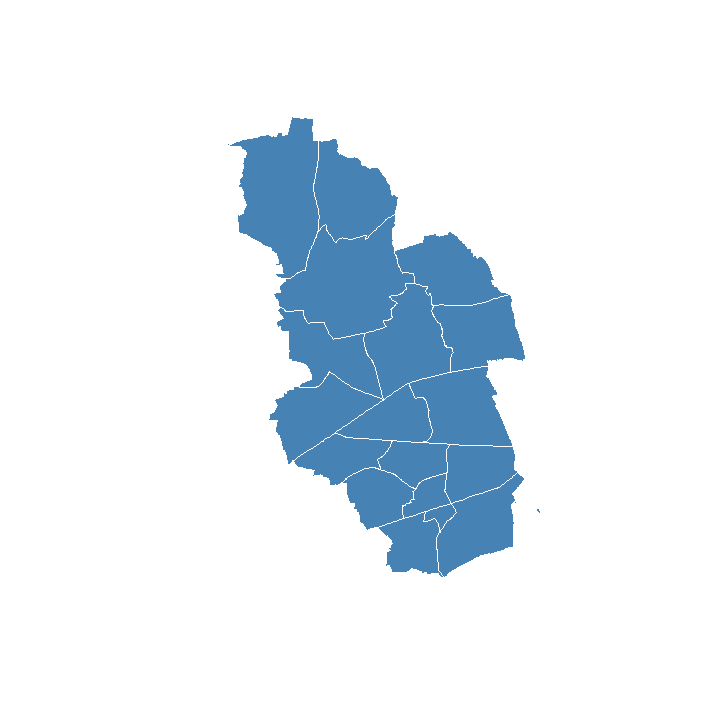

In [13]:
quarters <- de_load_geodata(dists[dists$format == "WFS_SRVC", ], layer = "stadtteil", crs = "EPSG:4326")
cat(nrow(quarters), "city quarters\n")
plot(sf::st_geometry(quarters), col = "steelblue", border = "white")

In [14]:
record <- de_get_dataset("eac1e504-9d63-4670-95b3-3ef04e22aa6e~~1")
gk <- record$summary
licences <- sort(unique(stats::na.omit(dists$license)))
cat("Source:    ", gk$title, " (catalogue ", gk$catalog, ")\n", sep = "")
cat("Publisher: ", if (is.na(gk$publisher)) paste("not named in the record; contact point", record$raw$contact_point[[1]]$url[[1]]) else gk$publisher, "\n", sep = "")
cat("Portal:    ", gk$portal_url, "\n", sep = "")
cat("Licence:   ", if (length(licences)) paste(licences, collapse = ", ") else "not stated on the portal (rights: no access restrictions)", "\n", sep = "")
cat("Retrieved: ", retrieved, "\n", sep = "")

Source:    Municipalities of Gelsenkirchen (catalogue gdi-de)


Publisher: not named in the record; contact point https://www.gelsenkirchen.de


Portal:    https://data.europa.eu/data/datasets/eac1e504-9d63-4670-95b3-3ef04e22aa6e~~1


Licence:   not stated on the portal (rights: no access restrictions)


Retrieved: 2026-11-28
